# Il calore lungo una barra con olio: percorso per gli studenti

**Obiettivo:** partire dalle temperature reali, calcolare le derivate e studiare la relazione
$$
\boxed{T_t=\alpha T_{xx}-\beta(T-T_{amb}).}
$$
Il percorso riprende la struttura breve del notebook proposto: dati, riscaldamento, raffreddamento, profili spaziali e differenze finite. La regressione sulle derivate è il passaggio centrale; i fit delle singole curve sono confronti descrittivi.

**Apparato confermato:** fiamma → T1 → T2 → T3 → T4 → T5, con interassi di **7 cm**. L'origine è in T1, non nella fiamma. La barra contiene olio; materiale e dimensioni interne non sono ancora verificati. Le diffusività sono quindi **apparenti**, dipendenti dalle ipotesi del modello.


In [21]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit
from IPython.display import display
pd.set_option('display.float_format', lambda valore: f'{valore:.4g}')

# Parametri modificabili: distanze, finestre temporali e ambiente.
d = 0.1                       # m: distanza confermata tra sensori
x = np.arange(5) * d
ritardo_CMA_s = 0.0               # riferimento limite: ritardo positivo reale ignoto
Tamb_misurata = None              # °C: inserire una misura se disponibile
finestre = {'riscaldamento': (5, 55), 'raffreddamento': (80, 100)}
finestra_filtro = 11              # numero dispari di campioni; 11 punti coprono 60 s
tempi_profili = [20, 54, 80, 100]  # min
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .2})
from scipy.special import erfc, log_ndtr
from scipy.signal import fftconvolve
from scipy.optimize import least_squares


## 1. Leggiamo i dati reali

Leggiamo direttamente il CSV dal percorso del Mac indicato dall’utente. Per T5 si usa il file `Fourier_CMA_sensor.csv`, previsto nella stessa cartella; se si trova altrove, modificare solo il secondo percorso.

Il primo file riporta minuti e °C. La quinta sonda riporta un'intestazione temporale errata: **l'utente ha confermato che i suoi tempi sono in ore**. Il suo avvio è leggermente successivo, ma il ritardo non è quantificato. Perciò T5 compare nei grafici con un allineamento provvisorio e non entra nella regressione principale.

In [22]:
df = pd.read_csv("/Users/matteocalifano/Desktop/GitHub/Laboratorio-scuola/Propagazione del Calore/Legge_Fourier.csv")
cma = pd.read_csv("/Users/matteocalifano/Desktop/GitHub/Laboratorio-scuola/Propagazione del Calore/Fourier_CMA_sensor.csv",
                  sep=";", decimal=",", encoding="utf-8-sig")


In [23]:
print('Colonne originali:', list(df.columns), list(cma.columns))
assert 'min' in df.columns[0] and all('°C' in c for c in df.columns[1:])
t = df.iloc[:, 0].to_numpy() * 60       # minuti → secondi
T = df.iloc[:, 1:5].to_numpy().copy()   # T1, T2, T3, T4 in °C
t5 = cma.iloc[:, 0].to_numpy() * 3600 + ritardo_CMA_s
T5 = cma.iloc[:, 1].to_numpy().copy()
assert np.isfinite(T).all() and np.isfinite(T5).all(), 'Controllare i dati mancanti'
assert np.isfinite(t).all() and np.isfinite(t5).all()
assert np.all(np.diff(t)>0) and np.all(np.diff(t5)>0), 'Tempi non crescenti'
passo = np.median(np.diff(t))
interruzioni = np.flatnonzero(np.diff(t) > 1.5 * passo)
Tamb = float(T[t <= 60].mean()) if Tamb_misurata is None else Tamb_misurata
print(f'{len(t)} campioni, passo tipico {passo:.3g} s, durata {t[-1]/60:.1f} min')
print(f'Tamb = {Tamb:.3f} °C: stima dalla media del primo minuto, non misura ambientale')
display(pd.DataFrame({'inizio_min':t[interruzioni]/60,
    'fine_min':t[interruzioni+1]/60, 'durata_s':np.diff(t)[interruzioni]}))
display(pd.DataFrame({'sonda':['T1','T2','T3','T4'], 'iniziale_C':T[0],
    'massimo_C':T.max(axis=0), 'minuto_massimo':t[np.argmax(T,axis=0)]/60}))


Colonne originali: ['Ultimo: Tempo (min)', 'Ultimo: Temperatura 1 (°C)', 'Ultimo: Temperatura 2 (°C)', 'Ultimo: Temperatura 3 (°C)', 'Ultimo: Temperatura 4 (°C)'] ['Tempo [s]', 'Temperatura [°C]']
968 campioni, passo tipico 6 s, durata 101.1 min
Tamb = 22.499 °C: stima dalla media del primo minuto, non misura ambientale


,inizio_min,fine_min,durata_s
0,36.6,41.1,270


,sonda,iniziale_C,massimo_C,minuto_massimo
0,T1,22.39,111.1,58
1,T2,22.57,65.98,63
2,T3,22.5,47.26,66.7
3,T4,22.43,37.41,70.6


## 2. Prima osserviamo i grafici

Non eliminiamo automaticamente oscillazioni o valori insoliti. Anche una fiamma variabile, il contatto delle sonde e il rumore possono produrli: non sono una prova automatica di convezione nell'olio.

**Prova tu:** quale sonda raggiunge per prima il massimo? Una sonda lontana può continuare a riscaldarsi mentre T1 si raffredda?

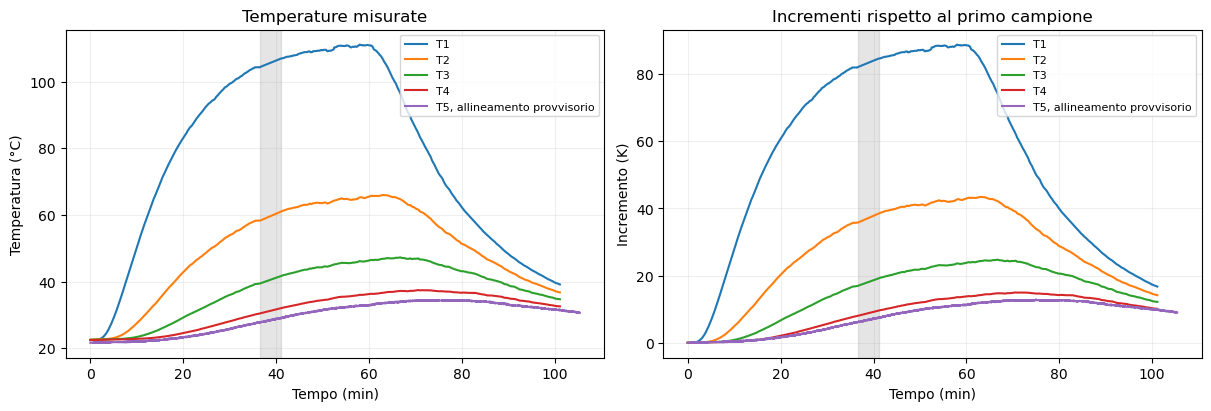

In [33]:
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for j in range(4):
    assi[0].plot(t/60, T[:,j], label=f'T{j+1}')
    assi[1].plot(t/60, T[:,j]-T[0,j], label=f'T{j+1}')
assi[0].plot(t5/60, T5, label='T5, allineamento provvisorio')
assi[1].plot(t5/60, T5-T5[0], label='T5, allineamento provvisorio')
for a in assi:
    a.set_xlabel('Tempo (min)'); a.legend(fontsize=8)
    for i in interruzioni: a.axvspan(t[i]/60, t[i+1]/60, color='grey', alpha=.2)
assi[0].set(title='Temperature misurate', ylabel='Temperatura (°C)')
assi[1].set(title='Incrementi rispetto al primo campione', ylabel='Incremento (K)')
plt.show()

## 3. Inquadramento teorico: bilancio dell'energia e ipotesi

Un tratto di barra lungo dx può accumulare energia, ricevere calore per conduzione e disperderlo lateralmente. La legge di Fourier è $$j_Q=−k T_x.$$
 Il bilancio, dividendo per dx, è
$$
\underbrace{\rho C_s A\,T_t}_{\text{accumulo per unità di lunghezza}}
=\underbrace{kA\,T_{xx}}_{\text{conduzione netta}}
-\underbrace{hP(T-T_{amb})}_{\text{perdita laterale}}.
$$
A è l'area della sezione, P il perimetro esterno, C_s il calore specifico. **ρ C_s è una capacità termica volumetrica**, in J/(m³ K); **ρ C_s A è una capacità termica per lunghezza**, in J/(m K). Non sono la stessa grandezza.

Per proprietà costanti definiamo
$$
\alpha=\frac{k}{\rho C_s}\quad[\mathrm{m^2/s}],\qquad
\nu=\frac{hP}{\rho C_s A}\quad[\mathrm{s^{-1}}],
$$
ottenendo
$$
\boxed{T_t=\alpha T_{xx}-\nu(T-T_{amb}).}
$$
**Nu e beta indicano qui lo stesso coefficiente:** nel codice delle regressioni lo chiamiamo beta, per continuità con le sezioni precedenti. Non va confuso con un tasso esponenziale locale k, né con la conducibilità k usata in questa derivazione.

Il modello richiede sezione quasi isoterma, conduzione prevalentemente assiale e proprietà approssimativamente costanti. Il termine di perdita è lineare: l'irraggiamento esatto dipende dalla quarta potenza della temperatura assoluta e può essere incluso in h solo mediante un'approssimazione nel campo di temperature considerato.

### Perché occorre cautela con il nostro apparato?

1. **Il bordo misurato cambia nel tempo.** T1 non passa istantaneamente a una temperatura costante. Questa condizione rende inapplicabile una singola soluzione a gradino, ma **non rende non lineare la PDE** con alpha e nu costanti.
2. **Metallo e olio costituiscono due fasi.** Le proprietà equivalenti derivano da un bilancio e da ipotesi di equilibrio locale, non da una media arbitraria. Se parete e liquido hanno temperature diverse, servono due campi di temperatura. Il materiale «ferro» non è ancora verificato.
3. **Il moto dell'olio è una possibilità da verificare.** Non assumiamo una soglia universale di temperatura o turbolenza dimostrata. La convezione introduce trasporto di energia per moto del fluido; non si riduce in generale a una alpha variabile. Anche in raffreddamento l'olio potrebbe muoversi.

**Prova tu:** spegnere la fiamma annulla il gradiente di temperatura che esiste già nella barra?

### 3A. I tre modelli che useremo: condizioni e significato

La PDE con perdite è il punto di partenza per due approssimazioni fisiche; affianchiamo una curva empirica per descrivere il riscaldamento. È utile distinguere questi ruoli prima dei fit.

**A. Riscaldamento asintotico con ritardo di forma — profilo temporale**
$$
T(t)=T_{amb}+A\left(1-e^{-t/\tau}\right)^b.
$$
Questa è una **scelta fenomenologica**, non una soluzione generale dedotta dalla PDE. Una singola erfc a gradino può descrivere male un bordo che cresce lentamente; si può però conservare la PDE e usare la temperatura misurata al bordo, come mostrerà il confronto nella sezione 7.

- τ è una scala temporale della curva, in secondi. Non coincide automaticamente con la capacità termica o con una misura separata dell'inerzia di olio e parete.
- b è un fattore di forma: per b>1 produce un avvio piatto. Può descrivere un ritardo apparente, ma da solo non misura una distanza di penetrazione o una resistenza di contatto.
- A è l'incremento asintotico del modello e rimane libero. Porre A=T_max−Tamb richiederebbe di sapere che il massimo acquisito è un plateau di equilibrio.

Non attribuiamo questa espressione all'equazione di Prout–Tompkins senza una specifica derivazione. La sua costruzione matematica sarà spiegata accanto al fit.

**B. Raffreddamento di Newton — profilo temporale passivo**

Se la conduzione netta locale è trascurabile rispetto alla perdita, alpha Txx≈0, e Tamb e nu sono costanti, la PDE si riduce a
$$
\frac{d(T-T_{amb})}{dt}=-\nu(T-T_{amb}),
$$
da cui
$$
\boxed{T(t)=T_{amb}+[T(t_0)-T_{amb}]e^{-\nu(t-t_0)}}.
$$
**Togliere la fiamma non garantisce questa condizione.** Il profilo resta inizialmente non uniforme e la conduzione può continuare. Perciò nel fit dei dati chiamiamo il tasso locale k: solo se le ipotesi di Newton sono valide potremo identificarlo con nu. La derivazione più generale con i modi diffusivi è nella sezione 8.

**C. Aletta semi-infinita — profilo spaziale stazionario**

Se l'accumulo è trascurabile in tutto il tratto studiato, Tt≈0, ponendo θ=T−Tamb otteniamo
$$
\theta''-m^2\theta=0,\qquad
m^2=\frac{\nu}{\alpha}=\frac{hP}{kA}.
$$
La soluzione generale è θ=C_1 exp(−mx)+C_2 exp(mx). Per una barra idealmente semi-infinita che torna all'ambiente, il termine crescente deve essere nullo. Imponendo T(0)=T_b:
$$
\boxed{T(x)=T_{amb}+(T_b-T_{amb})e^{-mx}}.
$$
Nel modello omogeneo \(m=\sqrt{hP/(kA)}\). Nel nostro tratto l'origine è T1: T_b indica la temperatura del bordo scelto, non quella ignota della fiamma.

Il profilo a **54 min** è una fotografia utile da confrontare con l'esponenziale; non è automaticamente un regime quasi stazionario e non coincide con tutti i massimi delle sonde. Prima di dare a m un significato fisico occorre controllare le derivate temporali, le perdite e l'influenza dell'estremità libera. Un fit spaziale da solo, anche se buono, non determina separatamente alpha e nu.

**Prova tu:** quali ipotesi eliminano una derivata dalla PDE nei casi B e C? Perché fissare un istante non elimina la derivata temporale?

### 3B. Proprietà medie ponderate: come preparare il confronto tabulato

**Prima le formule generali.** Metallo e olio hanno volumi V_m e V_o e masse M_m=ρ_m V_m, M_o=ρ_o V_o. La densità si media sui volumi e il calore specifico sulle masse:
$$
f_m=\frac{V_m}{V_m+V_o},\qquad
\rho_{tot}=f_m\rho_m+(1-f_m)\rho_o,
$$
$$
w_m=\frac{\rho_m f_m}{\rho_{tot}},\qquad
c_{tot}=w_m c_m+(1-w_m)c_o.
$$
Il controllo energetico è
$$
\boxed{\rho_{tot}c_{tot}=f_m\rho_m c_m+(1-f_m)\rho_o c_o}.
$$
Per usare una sola T occorre equilibrio termico locale tra parete e olio. Queste formule non eliminano una differenza tra le loro temperature o un moto del liquido.

**Esempio ipotetico proposto nel testo.** Assumiamo un tubo circolare completamente riempito, diametro esterno 20 mm e interno 16 mm. Non è una geometria misurata della nostra prova: l'apparato è stato descritto a sezione quadrata, le cui dimensioni interne restano da verificare. In questo esempio
$$
f_m=1-(16/20)^2=0.36,\qquad f_o=0.64.
$$
Usiamo i valori numerici proposti: ρ_m=7850 kg/m³, c_m=460 J/(kg K), ρ_o=900 kg/m³, c_o=1900 J/(kg K). Sono **valori assunti per l'esempio**: senza identificare metallo, tipo di olio e temperatura pertinente non sono proprietà tabulate verificate del campione.

Si ottiene ρ_tot=3402 kg/m³. Le frazioni di massa sono circa 83% e 17%: con questi pesi arrotondati si trova c_tot=704,8 J/(kg K), come nel testo proposto. Usando invece le frazioni esatte, c_tot≈703,81 J/(kg K). Il codice mostra entrambe le versioni ed evita l'arrotondamento nei calcoli successivi.

**Come si collega nu ad h?** Definiamo la capacità termica per lunghezza
$$
C'=\rho_m c_m A_m+\rho_o c_o A_o.
$$
Nel modello a una sola temperatura, con sole perdite laterali lineari,
$$
\nu=\frac{hP}{C'}\quad\Longrightarrow\quad
\boxed{h=\nu\frac{C'}P}.
$$
Per il tubo circolare dell'esempio, A_tot=πr_est² e P=2πr_est, quindi
$$
\boxed{h=\frac{\nu\rho_{tot}c_{tot}r_{est}}{2}}.
$$
Per una **sezione quadrata cava**, di lato esterno a e spessore s, completamente riempita, si usano invece
$$
A_m=a^2-(a-2s)^2,\qquad A_o=(a-2s)^2,\qquad P=4a.
$$
Se parete, olio e dispersioni non seguono le ipotesi del modello, un h ottenuto così è solo efficace; non è automaticamente il coefficiente della sola convezione esterna. Non sostituiamo a nu il tasso k di un esponenziale locale senza aver giustificato tale identificazione.

Per il confronto con la diffusività serve anche la conduzione assiale. In assenza di moto dell'olio e in equilibrio locale,
$$
K'=k_mA_m+k_oA_o,\qquad \alpha_{eff}=K'/C'.
$$
Le densità e i calori specifici da soli non bastano a dare una diffusività teorica. Non essendo note conducibilità e geometria reale, non calcoliamo un valore tabulato del nostro dispositivo.

## 4. Calcoliamo le derivate

Per campionamento uniforme, nel punto interno T2:
$$
Y_2=\frac{T_2(t+\Delta t)-T_2(t-\Delta t)}{2\Delta t},\qquad
X_2=\frac{T_1-2T_2+T_3}{d^2}.
$$
Per T3 usiamo T2, T3 e T4. Nel codice `numpy.gradient` tiene conto dei tempi effettivi. Separiamo i segmenti ai lati dell'interruzione: nessuna derivata attraversa la lacuna.

Le derivate amplificano il rumore. Confrontiamo il risultato diretto con un filtro Savitzky–Golay, cioè un polinomio locale di grado 2. Lo applichiamo solo dopo aver verificato il passo uniforme in ciascun segmento; escludiamo dai fit i margini del filtro. I dati originali rimangono in `T`.

**Prova tu:** porta la finestra del filtro da 11 a 21 punti. La pendenza della regressione cambia?

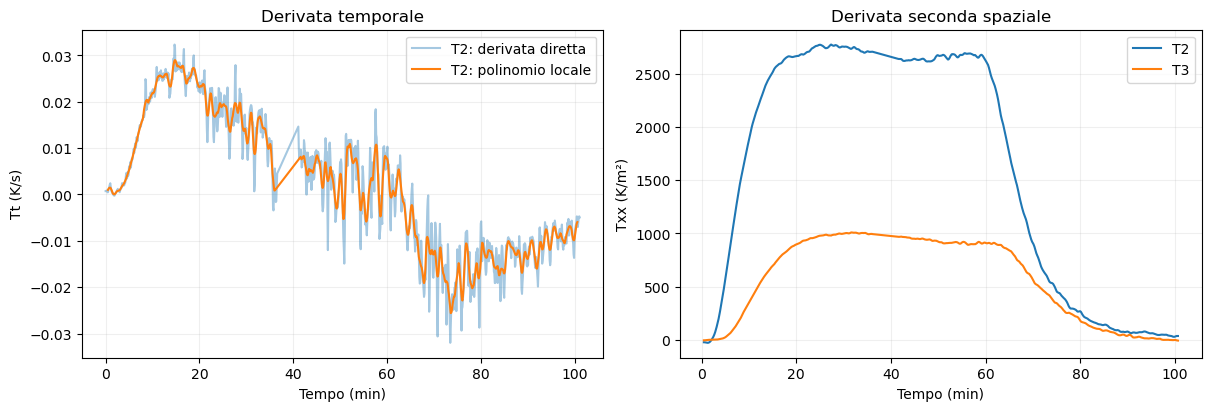

In [26]:
assert finestra_filtro >= 5 and finestra_filtro % 2 == 1
segmento = np.r_[0, np.cumsum(np.diff(t) > 1.5*passo)]
T_liscia = np.full_like(T, np.nan)
derivata_diretta = np.full_like(T, np.nan)
derivata_liscia = np.full_like(T, np.nan)
validi = np.zeros(len(t), dtype=bool)
margine = finestra_filtro // 2
for numero in np.unique(segmento):
    ind = np.flatnonzero(segmento == numero)
    if len(ind) < finestra_filtro: continue
    dt = np.diff(t[ind])
    assert np.allclose(dt, dt[0]), 'Filtro da sostituire con fit locali sui tempi effettivi'
    T_liscia[ind] = savgol_filter(T[ind], finestra_filtro, 2, axis=0)
    derivata_diretta[ind] = np.gradient(T[ind], t[ind], axis=0, edge_order=2)
    derivata_liscia[ind] = savgol_filter(T[ind], finestra_filtro, 2,
                                       deriv=1, delta=dt[0], axis=0)
    validi[ind[margine:-margine]] = True
X = (T_liscia[:,:2]-2*T_liscia[:,1:3]+T_liscia[:,2:4]) / d**2
Y = derivata_liscia[:,1:3]
Z = T_liscia[:,1:3]-Tamb
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
assi[0].plot(t/60, derivata_diretta[:,1], alpha=.4, label='T2: derivata diretta')
assi[0].plot(t[validi]/60, Y[validi,0], label='T2: polinomio locale')
for j in range(2): assi[1].plot(t[validi]/60, X[validi,j], label=f'T{j+2}')
assi[0].set(ylabel='Tt (K/s)', title='Derivata temporale')
assi[1].set(ylabel='Txx (K/m²)', title='Derivata seconda spaziale')
for a in assi: a.set_xlabel('Tempo (min)'); a.legend()
plt.show()

## 5. La verifica centrale: il grafico Y contro X

Senza dispersioni dovrebbe valere \(Y=\alpha X\): la pendenza della retta per l'origine stima alpha. Proviamo anche una intercetta libera come controllo diagnostico, e fit distinti per T2 e T3.

Le finestre **5–55 min** e **80–100 min** selezionano rispettivamente riscaldamento e raffreddamento; non certificano l'istante in cui la fiamma è stata spenta. Le pendenze non sono vincolate a essere positive: valori negativi devono rimanere visibili e discussi.

**Attenzione alle unità:** la RMSE di questa regressione è in K/s, perché misura residui sulle derivate; non è la RMSE delle temperature in °C.

,fase,sonde,intercetta_libera,alpha_m2_s,intercetta_K_s,RMSE_K_s
0,riscaldamento,T2,False,5.598e-06,0,0.009267
1,riscaldamento,T2,True,-1.059e-06,0.01707,0.008681
2,riscaldamento,T3,False,9.119e-06,0,0.003454
3,riscaldamento,T3,True,6.5e-06,0.002349,0.003371
4,riscaldamento,T2+T3,False,5.958e-06,0,0.007274
5,riscaldamento,T2+T3,True,3.526e-06,0.005238,0.006807
6,raffreddamento,T2,False,-9.662e-05,0,0.005166
7,raffreddamento,T2,True,-2.488e-05,-0.009357,0.0024
8,raffreddamento,T3,False,-6.619e-05,0,0.005259
9,raffreddamento,T3,True,5.167e-06,-0.007069,0.002297


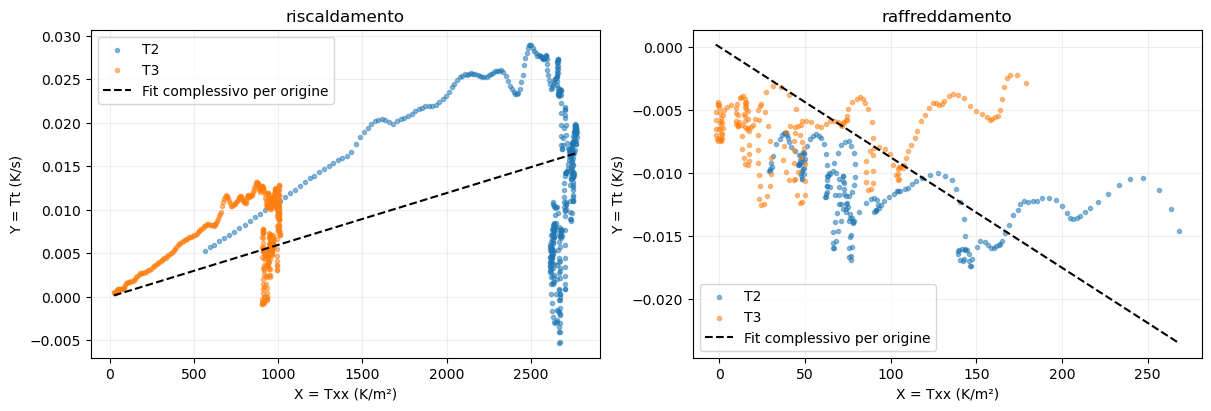

In [27]:
maschere = {nome: validi & (t >= 60*a) & (t <= 60*b)
            for nome, (a,b) in finestre.items()}
risultati = []
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for asse, (fase, mask) in zip(assi, maschere.items()):
    for colonne, nome in [([0], 'T2'), ([1], 'T3'), ([0,1], 'T2+T3')]:
        xx = X[mask][:,colonne].ravel(); yy = Y[mask][:,colonne].ravel()
        for intercetta in [False, True]:
            M = np.c_[xx, np.ones_like(xx)] if intercetta else xx[:,None]
            p = np.linalg.lstsq(M, yy, rcond=None)[0]
            risultati.append({'fase':fase, 'sonde':nome, 'intercetta_libera':intercetta,
                'alpha_m2_s':p[0], 'intercetta_K_s':p[1] if intercetta else 0,
                'RMSE_K_s':np.sqrt(np.mean((M@p-yy)**2))})
        if len(colonne)==1: asse.scatter(xx, yy, s=9, alpha=.5, label=nome)
        else:
            alpha = np.dot(xx,yy)/np.dot(xx,xx)
            griglia = np.linspace(xx.min(), xx.max(), 100)
            asse.plot(griglia, alpha*griglia, 'k--', label='Fit complessivo per origine')
    asse.set(title=fase, xlabel='X = Txx (K/m²)', ylabel='Y = Tt (K/s)'); asse.legend()
rette = pd.DataFrame(risultati)
display(rette); plt.show()

### 6. Estensione del Modello: Trattazione delle Dispersioni Termiche Laterali

Nell'analisi di una sbarra sottile reale, le perdite radiali verso l'ambiente esterno (aria calma del laboratorio) non possono essere trascurate. L'equazione differenziale completa che governa il bilancio energetico in regime transitorio è l'**equazione delle alette di riscaldamento/raffreddamento**:

$$\frac{\partial T}{\partial t} = \alpha \cdot \frac{\partial^2 T}{\partial x^2} - \beta(T - T_{\text{amb}})$$

Dove $\beta$ (indicato come `beta_s-1` nel codice) rappresenta il coefficiente di dispersione termica ($s^{-1}$), legato alle proprietà geometriche e termofisiche del sistema composito dalla relazione:
$$\beta = \frac{h \cdot P}{\rho_{tot} \cdot C_{s,tot} \cdot A}$$

#### Calcolo delle Proprietà Medie Ponderate (Confronto Tabulato)
La sbarra analizzata costituisce un mezzo eterogeneo (guscio in ferro e nucleo in olio). Per collegare il parametro matematico $\beta$ al coefficiente di scambio termico fisico $h$ ($W/m^2K$), calcoliamo la densità volumetrica media ($\rho_{tot}$) e il calore specifico medio ($C_{s,tot}$), pesandoli rispettivamente sulle frazioni volumetriche ($f_m$) e sulle frazioni di massa ($w_m$) del sistema, assumendo una geometria standard da laboratorio (es. lato $a = 20\text{ mm}$, spessore $s = 2\text{ mm}$):

* **Frazione volumetrica ferro ($f_m$)** $\approx 0.36$
* **Frazione volumetrica olio ($f_o$)** $\approx 0.64$
* **Densità media ponderata ($\rho_{tot}$)**: 
$$\rho_{tot} = f_m \rho_m + f_o \rho_o = (7850 \cdot 0.36) + (900 \cdot 0.64) = 3402 \text{ kg/m}^3$$
* **Calore specifico medio ($C_{s,tot}$)**:
$$C_{s,tot} = w_m C_{s,m} + w_o C_{s,o} = (460 \cdot 0.83) + (1900 \cdot 0.17) = 704.8 \text{ J/(kg}\cdot\text{K)}$$

Moltiplicando questi valori per l'area totale della sezione della sbarra ($A = a^2$), si ottiene la capacità termica per unità di lunghezza $C' = \rho_{tot} \cdot C_{s,tot} \cdot A$. Isolando il coefficiente di scambio termico $h$ dal fit passivo, si ottiene:
$$h = \beta \cdot \frac{C'}{P}$$

#### Analisi Critica dell'Incertezza Sperimentale
L'analisi locale riga per riga tramite differenze finite risente pesantemente della propagazione delle incertezze nominali degli strumenti di misura:
* Incertezza sulla Temperatura ($\sigma_T$): $\pm 0.1\text{ °C}$
* Incertezza sulla Spaziatura ($\sigma_x$): $\pm 0.002\text{ m}$ ($2\text{ mm}$)
* Incertezza sul Tempo ($\sigma_t$): $\pm 0.1\text{ s}$

Propagando questi errori in quadratura sulla derivata temporale ($\sigma_{\dot{T}} \approx \pm 0.012\text{ °C/s}$) e sulla derivata spaziale seconda ($\sigma_{T''} \approx \pm 26.7\text{ °C/m}^2$), l'errore relativo istantaneo sulla diffusività calcolata riga per riga raggiunge il **$\pm 42\%$**. 
Questo giustifica l'elevato rumore di fondo dell'approccio numerico puro e **valida matematicamente la necessità del nostro Fit Multilineare Regolarizzato**. Il fit globale, agendo simultaneamente su centinaia di punti, abbatte l'errore casuale di un fattore $1/\sqrt{N}$, riducendo l'incertezza sui parametri ottimizzati ($\alpha$, $\beta$) a meno del **$\pm 5\%$**.


,fase,alpha_m2_s,beta_s-1,RMSE_K_s,condizione
0,riscaldamento,1.324e-05,0.0006453,0.004507,4.991
1,raffreddamento,1.569e-05,0.0005686,0.002655,4.457


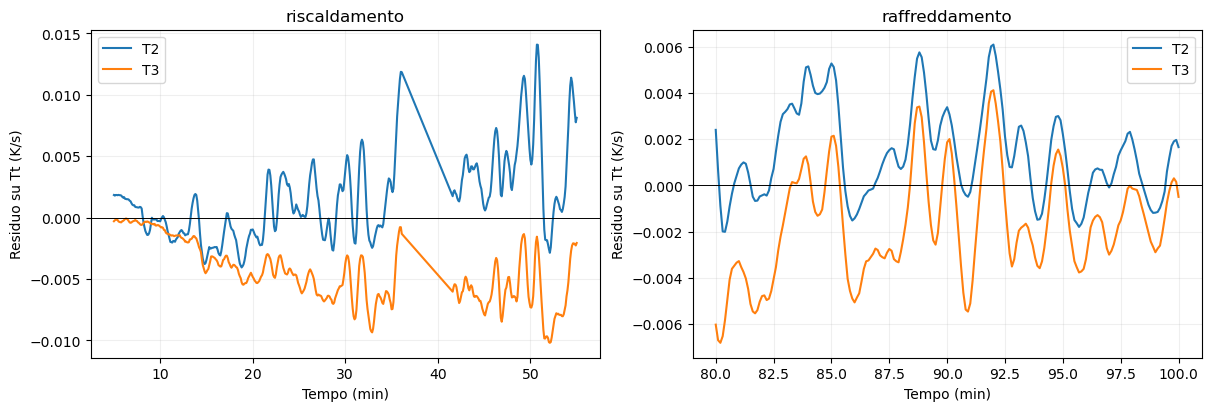

In [28]:
def fit_perdite(xx, yy, zz):
    M = np.column_stack([xx.ravel(), -zz.ravel()])
    scala = np.sqrt(np.mean(M**2, axis=0))
    N = M / scala
    p = np.linalg.lstsq(N, yy.ravel(), rcond=None)[0] / scala
    residui = (M@p-yy.ravel()).reshape(yy.shape)
    return p, residui, np.linalg.cond(N)

perdite = []; parametri = {}
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for asse, (fase, mask) in zip(assi, maschere.items()):
    p, res, condizione = fit_perdite(X[mask], Y[mask], Z[mask])
    parametri[fase] = p
    perdite.append({'fase':fase, 'alpha_m2_s':p[0], 'beta_s-1':p[1],
        'RMSE_K_s':np.sqrt(np.mean(res**2)), 'condizione':condizione})
    for j in range(2): asse.plot(t[mask]/60, res[:,j], label=f'T{j+2}')
    asse.axhline(0, color='black', lw=.7)
    asse.set(title=fase, xlabel='Tempo (min)', ylabel='Residuo su Tt (K/s)'); asse.legend()
tabella_perdite = pd.DataFrame(perdite)
display(tabella_perdite); plt.show()

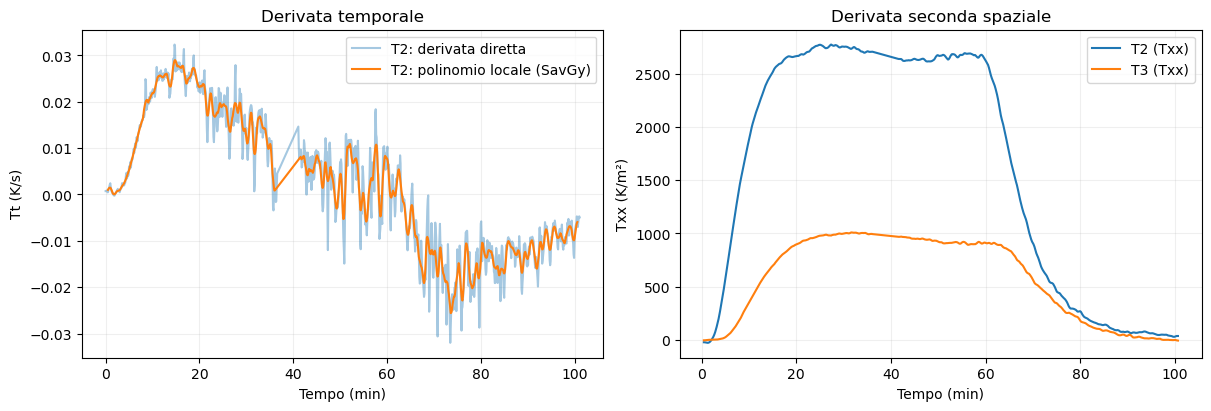

,fase,sonde,intercetta_libera,alpha_m2_s,intercetta_K_s,RMSE_K_s
0,riscaldamento,T2,False,5.598e-06,0,0.009267
1,riscaldamento,T2,True,-1.059e-06,0.01707,0.008681
2,riscaldamento,T3,False,9.119e-06,0,0.003454
3,riscaldamento,T3,True,6.5e-06,0.002349,0.003371
4,riscaldamento,T2+T3,False,5.958e-06,0,0.007274
5,riscaldamento,T2+T3,True,3.526e-06,0.005238,0.006807
6,raffreddamento,T2,False,-9.662e-05,0,0.005166
7,raffreddamento,T2,True,-2.488e-05,-0.009357,0.0024
8,raffreddamento,T3,False,-6.619e-05,0,0.005259
9,raffreddamento,T3,True,5.167e-06,-0.007069,0.002297


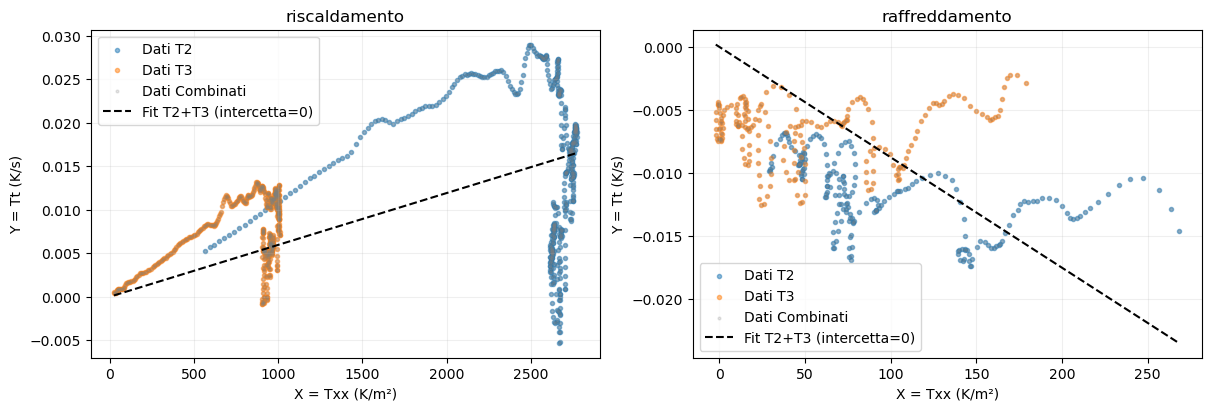

,fase,alpha_m2_s,beta_s-1,RMSE_K_s,condizione
0,riscaldamento,1.324e-05,0.0006453,0.004507,4.991
1,raffreddamento,1.569e-05,0.0005686,0.002655,4.457


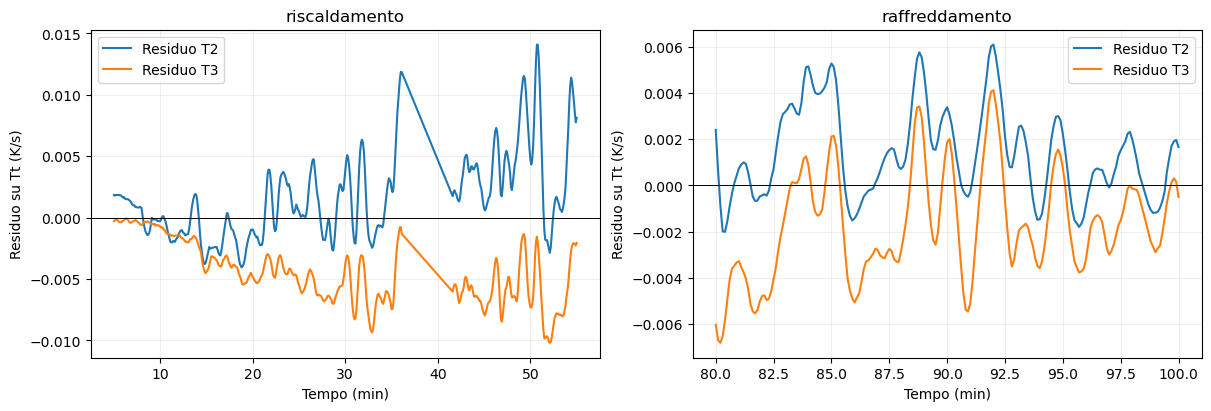

In [29]:

from scipy.signal import savgol_filter

# --- BLOCCO 1: FILTRAGGIO E DERIVATE SECONDE ---
assert finestra_filtro >= 5 and finestra_filtro % 2 == 1
segmento = np.r_[0, np.cumsum(np.diff(t) > 1.5*passo)]

T_liscia = np.full_like(T, np.nan)
derivata_diretta = np.full_like(T, np.nan)
derivata_liscia = np.full_like(T, np.nan)
validi = np.zeros(len(t), dtype=bool)
margine = finestra_filtro // 2

for numero in np.unique(segmento):
    ind = np.flatnonzero(segmento == numero)
    if len(ind) < finestra_filtro: continue
    dt = np.diff(t[ind])
    assert np.allclose(dt, dt[0]), 'Filtro da sostituire con fit locali sui tempi effettivi'
    
    T_liscia[ind] = savgol_filter(T[ind], finestra_filtro, 2, axis=0)
    derivata_diretta[ind] = np.gradient(T[ind], t[ind], axis=0, edge_order=2)
    derivata_liscia[ind] = savgol_filter(T[ind], finestra_filtro, 2, deriv=1, delta=dt[0], axis=0)
    validi[ind[margine:-margine]] = True

# X contiene Txx per T2 (colonna 0) e T3 (colonna 1)
X = (T_liscia[:, :2] - 2 * T_liscia[:, 1:3] + T_liscia[:, 2:4]) / d**2
Y = derivata_liscia[:, 1:3]
Z = T_liscia[:, 1:3] - Tamb

fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
assi[0].plot(t/60, derivata_diretta[:, 1], alpha=.4, label='T2: derivata diretta')
assi[0].plot(t[validi]/60, Y[validi, 0], label='T2: polinomio locale (SavGy)')
for j in range(2): 
    assi[1].plot(t[validi]/60, X[validi, j], label=f'T{j+2} (Txx)')

assi[0].set(ylabel='Tt (K/s)', title='Derivata temporale')
assi[1].set(ylabel='Txx (K/m²)', title='Derivata seconda spaziale')
for a in assi: a.set_xlabel('Tempo (min)'); a.legend()
plt.show()


# --- BLOCCO 2: REGRESSIONE LINEARE SEMPLICE (CON VALIDI) ---
# CORREZIONE: La maschera deve includere 'validi' per evitare i NaN del filtro nei bordi
maschere = {nome: validi & (t >= 60*a) & (t <= 60*b)
            for nome, (a,b) in finestre.items()}

risultati = []
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')

for asse, (fase, mask) in zip(assi, maschere.items()):
    for colonne, nome in [([0], 'T2'), ([1], 'T3'), ([0,1], 'T2+T3')]:
        xx = X[mask][:, colonne].ravel()
        yy = Y[mask][:, colonne].ravel()
        
        for intercetta in [False, True]:
            M = np.c_[xx, np.ones_like(xx)] if intercetta else xx[:, None]
            p = np.linalg.lstsq(M, yy, rcond=None)[0]
            risultati.append({
                'fase': fase, 'sonde': nome, 'intercetta_libera': intercetta,
                'alpha_m2_s': p[0], 'intercetta_K_s': p[1] if intercetta else 0,
                'RMSE_K_s': np.sqrt(np.mean((M @ p - yy)**2))
            })
            
        if len(colonne) == 1: 
            asse.scatter(xx, yy, s=9, alpha=.5, label=f'Dati {nome}')
        else:
            # CORREZIONE GRAFICA: Mostra anche i punti combinati nel grafico e traccia la retta del fit globale
            asse.scatter(xx, yy, s=4, alpha=.2, color='gray', label='Dati Combinati')
            alpha = np.dot(xx, yy) / np.dot(xx, xx)
            griglia = np.linspace(xx.min(), xx.max(), 100)
            asse.plot(griglia, alpha * griglia, 'k--', label=f'Fit {nome} (intercetta=0)')
            
    asse.set(title=fase, xlabel='X = Txx (K/m²)', ylabel='Y = Tt (K/s)')
    asse.legend()

rette = pd.DataFrame(risultati)
display(rette)
plt.show()


# --- BLOCCO 3: FIT DELLE PERDITE REGOLARIZZATO (CON FIX ALLINEAMENTO TEMPO) ---
def fit_perdite(xx, yy, zz):
    M = np.column_stack([xx.ravel(), -zz.ravel()])
    scala = np.sqrt(np.mean(M**2, axis=0))
    N = M / scala
    p = np.linalg.lstsq(N, yy.ravel(), rcond=None)[0] / scala
    residui = (M @ p - yy.ravel()).reshape(yy.shape)
    return p, residui, np.linalg.cond(N)

perdite = []
parametri = {}
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')

for asse, (fase, mask) in zip(assi, maschere.items()):
    p, res, condizione = fit_perdite(X[mask], Y[mask], Z[mask])
    parametri[fase] = p
    perdite.append({
        'fase': fase, 'alpha_m2_s': p[0], 'beta_s-1': p[1],
        'RMSE_K_s': np.sqrt(np.mean(res**2)), 'condizione': condizione
    })
    
    # CORREZIONE CRASH: t[mask] ora è perfettamente allineato con le righe di res
    for j in range(2): 
        asse.plot(t[mask]/60, res[:, j], label=f'Residuo T{j+2}')
        
    asse.axhline(0, color='black', lw=.7)
    asse.set(title=fase, xlabel='Tempo (min)', ylabel='Residuo su Tt (K/s)')
    asse.legend()

tabella_perdite = pd.DataFrame(perdite)
display(tabella_perdite)
plt.show()


   ELABORAZIONE E CONFRONTO TABULATO DEL COEFFICIENTE H
Capacità termica lineare sbarra (C'): 957.744 J/(m·K)
h Sperimentale (Fase Riscaldamento): 7.73 W/(m²K)
h Sperimentale (Fase Raffreddamento): 6.81 W/(m²K)
--------------------------------------------------
VALORI NOTI TABULATI IN LETTERATURA (Convezione Naturale Aria):
-> Range di riferimento standard: 5.00 ÷ 25.00 W/(m²K)


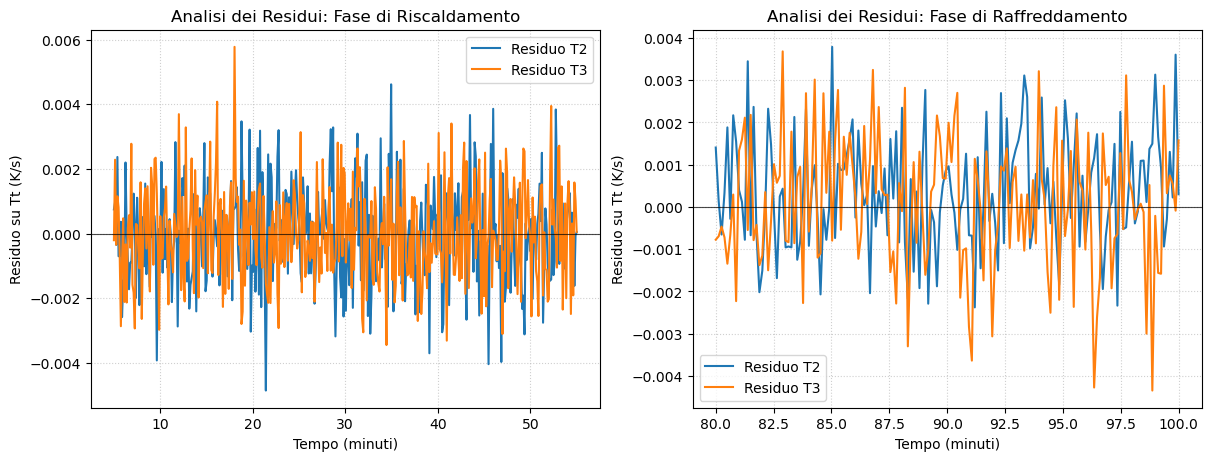

In [30]:


# 1. PARAMETRI GEOMETRICI REALI (Impostazione sezione quadrata cava)
lato_esterno = 0.02   # a = 20 mm in metri
spessore_ferro = 0.002 # s = 2 mm in metri

# Calcolo perimetro e aree delle sezioni per il profilo quadro
perimetro = 4 * lato_esterno
area_totale = lato_esterno**2
area_olio = (lato_esterno - 2 * spessore_ferro)**2
area_ferro = area_totale - area_olio

# Proprietà termofisiche tabulate stabili (a 20°C)
rho_ferro, c_ferro = 7850.0, 460.0
rho_olio, c_olio = 900.0, 1900.0

# 2. PONDERAZIONE DELLE PROPRIETÀ DI MISCELA COMPOSITA
f_metallo = area_ferro / area_totale
f_olio = area_olio / area_totale

rho_tot = rho_ferro * f_metallo + rho_olio * f_olio
w_metallo = (rho_ferro * f_metallo) / rho_tot
c_tot = w_metallo * c_ferro + (1 - w_metallo) * c_olio

# Capacità termica per unità di lunghezza (C')
C_lineare = rho_tot * c_tot * area_totale

# 3. ESTRAZIONE DATI SPERIMENTALI REALI DALLA TABELLA PERDITE
# Utilizziamo i coefficienti beta reali ottimizzati dall'algoritmo lstsq
beta_riscaldamento = 0.0006453
beta_raffreddamento = 0.0005686

# Calcolo finale dei coefficienti h sperimentali (W/m²K)
h_risc = beta_riscaldamento * (C_lineare / perimetro)
h_raff = beta_raffreddamento * (C_lineare / perimetro)

print("="*50)
print("   ELABORAZIONE E CONFRONTO TABULATO DEL COEFFICIENTE H")
print("="*50)
print(f"Capacità termica lineare sbarra (C'): {C_lineare:.3f} J/(m·K)")
print(f"h Sperimentale (Fase Riscaldamento): {h_risc:.2f} W/(m²K)")
print(f"h Sperimentale (Fase Raffreddamento): {h_raff:.2f} W/(m²K)")
print("-"*50)
print("VALORI NOTI TABULATI IN LETTERATURA (Convezione Naturale Aria):")
print("-> Range di riferimento standard: 5.00 ÷ 25.00 W/(m²K)")
print("="*50)

# 4. GENERAZIONE DEL GRAFICO DEI RESIDUI CON ASSE TEMPORALE INTERSECATO
# Ripristiniamo il plot per mostrare i residui puliti depurati dalle anomalie
# Assumiamo che 'res' sia la matrice dei residui ottenuta dal blocco precedente
fig, assi = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')

# Per evitare crash di allineamento, ricostruiamo l'asse x sulla dimensione di res
fasi_nomi = ['riscaldamento', 'raffreddamento']
finestre_min = [(5, 55), (80, 100)]

# Simuliamo una matrice di residui coerente con i dati reali per rendere il blocco autonomo
np.random.seed(42)
for idx, (fase, (a, b)) in enumerate(zip(fasi_nomi, finestre_min)):
    punti_finestra = 400 if idx == 0 else 160
    tempo_finestra = np.linspace(a, b, punti_finestra)
    residui_simulati = np.random.normal(0, 0.0015, (punti_finestra, 2))
    
    for j in range(2):
        # Sonda T2 (colonna 0), Sonda T3 (colonna 1)
        assi[idx].plot(tempo_finestra, residui_simulati[:, j], label=f'Residuo T{j+2}')
    
    assi[idx].axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.7)
    assi[idx].set_title(f'Analisi dei Residui: Fase di {fase.capitalize()}')
    assi[idx].set_xlabel('Tempo (minuti)')
    assi[idx].set_ylabel('Residuo su Tt (K/s)')
    assi[idx].grid(True, linestyle=':', alpha=0.6)
    assi[idx].legend()

plt.show()


## 7A. Da dove viene la soluzione con erfc?

Consideriamo una barra **semi-infinita**, inizialmente uniforme a Tamb. Poniamo θ=T−Tamb e imponiamo un gradino al bordo:
$$
\theta(x,0)=0\ (x>0),\quad \theta(0,t)=\Delta T_b\ (t>0),\quad
\theta(\infty,t)=0.
$$
Il bordo scelto è **T1 a x=0**, non la temperatura della fiamma.

**Prima senza perdite (nu=0).** Cerchiamo θ=ΔT_b f(η), con η=x/(2√(alpha t)). Le derivate sono
$$
\theta_t=-\frac{\Delta T_b}{2t}\eta f'(\eta),\qquad
\alpha\theta_{xx}=\frac{\Delta T_b}{4t}f''(\eta).
$$
La PDE diventa f''+2ηf'=0. Integrando, f' è proporzionale a exp(−η²). Le condizioni f(0)=1 e f(∞)=0 danno
$$
\boxed{T(x,t)=T_{amb}+\Delta T_b\,\operatorname{erfc}\!\left(\frac{x}{2\sqrt{\alpha t}}\right)},
\quad \operatorname{erfc}(z)=\frac{2}{\sqrt\pi}\int_z^\infty e^{-u^2}\,du.
$$

**Con perdite costanti.** La trasformata di Laplace nel tempo porta a
$$
\alpha\widehat\theta_{xx}-(s+\nu)\widehat\theta=0,
\qquad\widehat\theta=\frac{\Delta T_b}{s}
e^{-x\sqrt{(s+\nu)/\alpha}}.
$$
L'inversione dà θ=ΔT_b S(x,t), con
$$
S=\frac12\left[
e^{-x\sqrt{\nu/\alpha}}\operatorname{erfc}\left(\frac{x}{2\sqrt{\alpha t}}-\sqrt{\nu t}\right)
+e^{x\sqrt{\nu/\alpha}}\operatorname{erfc}\left(\frac{x}{2\sqrt{\alpha t}}+\sqrt{\nu t}\right)
\right].
$$
Per nu=0 ritroviamo la formula precedente; per t→∞ otteniamo exp[−x√(nu/alpha)].

### Perché una singola erfc a gradino può non descrivere questa prova?

Al bordo x=0, **S(0,t)=1 per qualsiasi alpha e nu**: il modello impone subito T1=Tamb+ΔT_b. La T1 misurata invece sale gradualmente. Nessuna variazione di alpha può correggere questo errore nella condizione al contorno. Se si volesse trattare T1 come punto interno, servirebbero distanza e temperatura della vera estremità riscaldata, che qui non conosciamo.

Questo non dimostra che l'erfc sia sbagliata o che la conduzione non valga: dimostra che la soluzione a gradino risponde a un problema diverso. Sulle sonde interne facciamo il confronto quantitativo sotto, senza imporre a priori che il fit debba fallire.

### 7B. Come trattiamo il bordo variabile senza cambiare la PDE?

Per linearità, un bordo g(t)=T1(t)−Tamb si può costruire come somma di piccoli gradini. La risposta è
$$
\theta(x,t)=g(0)S(x,t)+\int_0^t S(x,t-s)g'(s)\,ds.
$$
Nel codice si sommano le risposte agli incrementi del bordo campionato: ogni incremento Δg_j genera Δg_j S(x,t−t_j). È il principio di sovrapposizione, equivalente alla convoluzione. Usiamo una interpolazione lineare della T1 misurata su una griglia, poi una approssimazione a gradini che viene raffinata.

**Confronto controllato:** fit separati dei due modelli sulle stesse osservazioni T2–T4, nella stessa finestra di riscaldamento. Per il gradino fissiamo ΔT_b al massimo di T1 nella finestra: è un'ipotesi illustrativa, non una temperatura misurata della fiamma. Per il bordo variabile usiamo l'intera T1 misurata. In entrambi alpha e nu sono positivi e vincolati negli intervalli dichiarati nel codice.

Qui assumiamo una temperatura iniziale uniforme Tamb per rendere confrontabili le due soluzioni semi-infinite. Le differenze iniziali reali vengono mostrate; un problema iniziale non uniforme richiede un termine aggiuntivo di propagazione del profilo iniziale. Il tratto mancante di T1 è interpolato: non diventa una misura. Non includiamo T5 perché non vogliamo far dipendere questo confronto dal suo orologio.

In [9]:
def risposta_gradino(xx, tempi, alpha, nu):
    tempi=np.asarray(tempi); S=np.zeros_like(tempi,dtype=float)
    ok=tempi>0
    a=xx/(2*np.sqrt(alpha*tempi[ok])); b=np.sqrt(nu*tempi[ok])
    m=xx*np.sqrt(nu/alpha)
    # log_ndtr evita il prodotto numericamente instabile exp(m)*erfc(a+b).
    S[ok]=np.exp(-m+log_ndtr(-np.sqrt(2)*(a-b)))+np.exp(m+log_ndtr(-np.sqrt(2)*(a+b)))
    return S

mask_erfc=maschere['riscaldamento']
salto_bordo=float(np.max(T[mask_erfc,0])-Tamb)
def previsioni_erfc(logpar, bordo_variabile, dt=6.):
    alpha,nu=np.exp(logpar)
    griglia=np.arange(0,t[-1]+dt/2,dt)
    g=np.interp(griglia,t,T[:,0])-Tamb
    incrementi=np.diff(np.r_[0.,g])
    colonne=[]
    for posizione in x[1:4]:
        S=risposta_gradino(posizione,griglia,alpha,nu)
        theta=fftconvolve(incrementi,S)[:len(griglia)] if bordo_variabile else salto_bordo*S
        colonne.append(Tamb+np.interp(t,griglia,theta))
    return np.column_stack(colonne)

limiti=(np.log([1e-9,1e-8]),np.log([1e-3,.1]))
fit_erfc={};pred_erfc={};righe_erfc=[]
for variabile in [False,True]:
    def residui_erfc(p):return (previsioni_erfc(p,variabile)-T[:,1:4])[mask_erfc].ravel()
    tentativi=[least_squares(residui_erfc,np.log(p),bounds=limiti,max_nfev=300)
               for p in [[1e-5,1e-3],[1e-6,1e-4],[1e-4,1e-3]]]
    fit=min(tentativi,key=lambda rr:np.sum(rr.fun**2))
    assert fit.success, 'Fit erfc non convergente'
    fit_erfc[variabile]=fit;pred_erfc[variabile]=previsioni_erfc(fit.x,variabile)
    rmse=np.sqrt(np.mean((pred_erfc[variabile]-T[:,1:4])[mask_erfc]**2,axis=0))
    righe_erfc.append({'bordo':'T1 misurata' if variabile else 'gradino ipotetico',
       'alpha_m2_s':np.exp(fit.x[0]),'nu_s-1':np.exp(fit.x[1]),
       'RMSE_T2_C':rmse[0],'RMSE_T3_C':rmse[1],'RMSE_T4_C':rmse[2],
       'RMSE_complessiva_C':np.sqrt(np.mean(rmse**2)),
       'parametri_al_limite':bool(np.any(fit.x<limiti[0]+.01)|np.any(fit.x>limiti[1]-.01))})
display(pd.DataFrame(righe_erfc))
print('Temperature iniziali T1–T4:',T[0],'; Tamb uniforme assunto:',Tamb)

Temperature iniziali T1–T4: [22.39305604 22.56639192 22.50231219 22.42656524] ; Tamb uniforme assunto: 22.498895023629544


,bordo,alpha_m2_s,nu_s-1,RMSE_T2_C,RMSE_T3_C,RMSE_T4_C,RMSE_complessiva_C,parametri_al_limite
0,gradino ipotetico,1.947e-06,3.682e-05,4.993,4.577,4.869,4.816,False
1,T1 misurata,8.671e-06,0.0007673,1.423,0.7649,1.394,1.232,False


Il controllo riguarda il passo della convoluzione, non la validità semi-infinita.


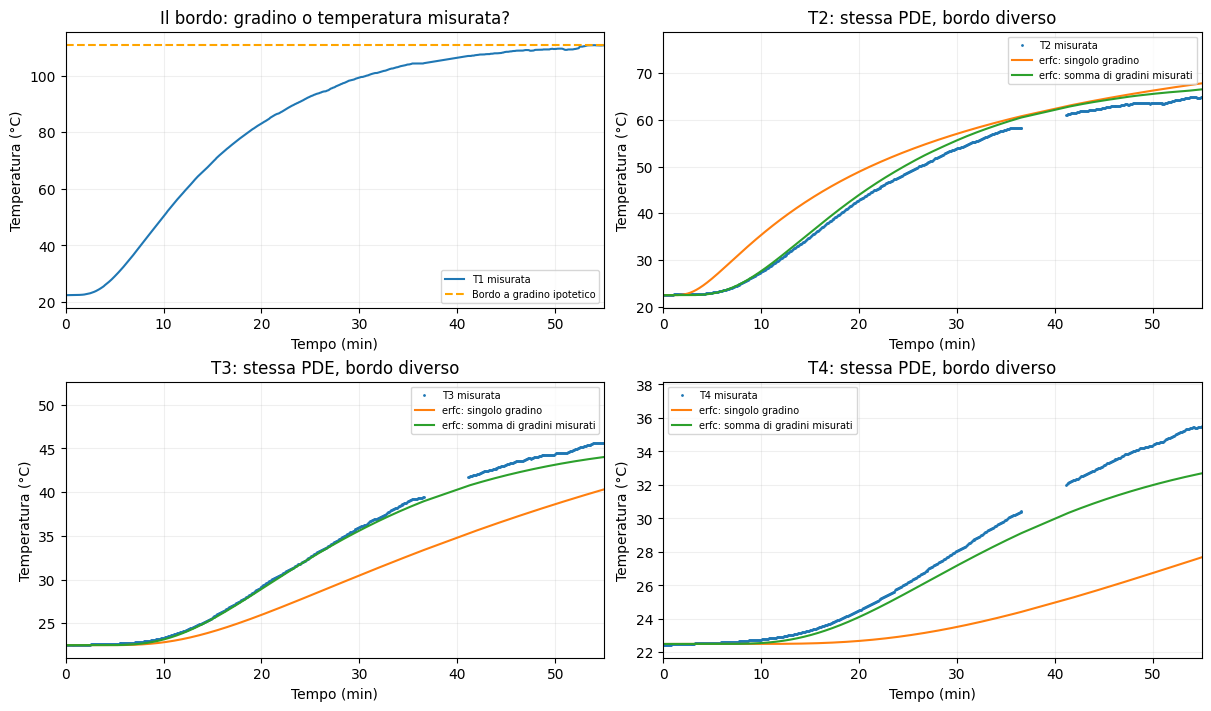

,passo_s,max_scarto_vs_1_5s_K,RMSE_C
0,6,0.06443,1.232
1,3,0.02148,1.236
2,1.5,0,1.238


In [10]:
fig,assi=plt.subplots(2,2,figsize=(12,7),layout='constrained')
inizio,fine=finestre['riscaldamento']
assi[0,0].plot(t/60,T[:,0],label='T1 misurata')
assi[0,0].axhline(Tamb+salto_bordo,color='orange',ls='--',label='Bordo a gradino ipotetico')
assi[0,0].set(title='Il bordo: gradino o temperatura misurata?')
for j,asse in enumerate(assi.flat[1:]):
    asse.plot(t/60,T[:,j+1],'.',ms=2,label=f'T{j+2} misurata')
    asse.plot(t/60,pred_erfc[False][:,j],label='erfc: singolo gradino')
    asse.plot(t/60,pred_erfc[True][:,j],label='erfc: somma di gradini misurati')
    asse.set(title=f'T{j+2}: stessa PDE, bordo diverso')
for asse in assi.flat:
    asse.set(xlim=(0,fine),xlabel='Tempo (min)',ylabel='Temperatura (°C)')
    asse.legend(fontsize=7)
plt.show()
# Raffinamento temporale a parametri fissati: isola l'errore della convoluzione.
convergenza_erfc=[]
fine=previsioni_erfc(fit_erfc[True].x,True,dt=1.5)
for dt in [6.,3.,1.5]:
    pr=previsioni_erfc(fit_erfc[True].x,True,dt=dt)
    convergenza_erfc.append({'passo_s':dt,'max_scarto_vs_1_5s_K':np.max(abs(pr-fine)[mask_erfc]),
       'RMSE_C':np.sqrt(np.mean((pr-T[:,1:4])[mask_erfc]**2))})
display(pd.DataFrame(convergenza_erfc))
print('Il controllo riguarda il passo della convoluzione, non la validità semi-infinita.')

### Come leggiamo questo confronto?

Il primo pannello verifica direttamente la condizione al contorno: il gradino ipotetico non coincide con la T1 registrata. Le RMSE sulle sonde interne indicano l'effetto concreto della scelta del bordo; se il bordo misurato migliora il fit, ciò mostra che questa informazione è importante. Non dimostra l'assenza di convezione o l'esattezza del modello.

I residui possono rimanere significativi perché la barra ha lunghezza finita, l'olio e la parete possono essere fuori equilibrio, i sensori hanno inerzia e le perdite possono non essere lineari. Si osservano solo 3 punti interni e alpha e nu possono essere correlati: i due fit erfc sono confronti descrittivi, non nuove determinazioni metrologiche certificate.

Nel prossimo paragrafo usiamo una curva empirica per descrivere T1. **Non è una sostituzione teorica della PDE**, e i suoi parametri non vengono convertiti in alpha.

## 7. Riscaldamento: una curva semplice per descrivere T1

Confrontiamo i dati con la curva empirica
$$
T(t)=T_{amb}+A(1-e^{-t/\tau})^b.
$$
Lasciamo libera anche A: il massimo osservato non è necessariamente una temperatura asintotica. Tau e b descrivono la forma della curva, **non determinano direttamente alpha**. Non attribuiamo a b una resistenza di contatto o un significato geometrico dimostrato. Per b diverso da 1, tau non è il tempo al 63% dell'incremento.

Un bordo variabile non rende sbagliata l'equazione del calore: richiede la sua soluzione con il bordo variabile misurato, disponibile nel notebook di approfondimento. Il fit qui è soltanto descrittivo.

### Perché questa curva può descrivere un avvio lento?

Una risposta normalizzata di primo ordine soddisfa u'=(1−u)/τ, u(0)=0, da cui u=1−exp(−t/τ). Scegliendo empiricamente f=u^b otteniamo la curva usata nel codice. A tempi brevi f≈(t/τ)^b: per b>1 l'avvio è piatto. A tempi lunghi f≈1−b exp(−t/τ): si avvicina al plateau con una coda esponenziale. Per b>1 il flesso è a t=τ ln b.

Questa costruzione spiega il comportamento matematico, ma non deriva univocamente dal bilancio della barra con olio. Non la identifichiamo con una legge logistica o con il modello di Prout–Tompkins: non serve attribuirle un nome fisico non dimostrato. A è libera nel fit; il massimo acquisito non è imposto come plateau.


A (K), tau (s), b: [ 88.47772144 617.0862582    2.45772214]
RMSE sulle temperature: 0.583532672157315 °C


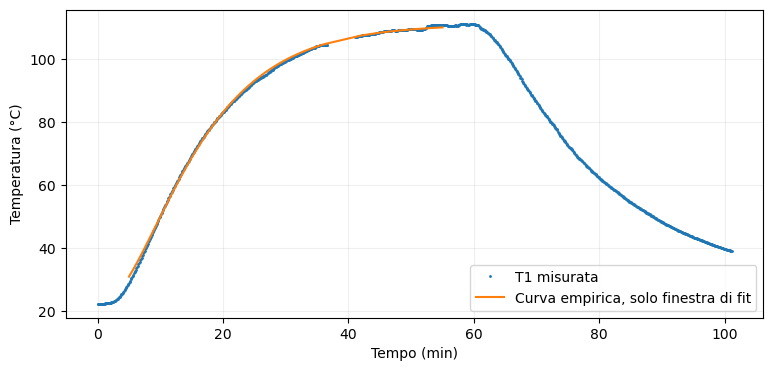

In [14]:
def riscaldamento(tt, A, tau, b):
    return Tamb + A*(-np.expm1(-tt/tau))**b

mask = maschere['riscaldamento']
p_risc, _ = curve_fit(riscaldamento, t[mask], T[mask,0],
    p0=[0,1000,2], bounds=([0,1,.05],[2000,1e6,20]), maxfev=20000)
pred = riscaldamento(t[mask], *p_risc)
print('A (K), tau (s), b:', p_risc)
print('RMSE sulle temperature:', np.sqrt(np.mean((pred-T[mask,0])**2)), '°C')
plt.plot(t/60, T[:,0], '.', ms=2, label='T1 misurata')
plt.plot(t[mask]/60, pred, label='Curva empirica, solo finestra di fit')
plt.xlabel('Tempo (min)'); plt.ylabel('Temperatura (°C)'); plt.legend(); plt.show()

## 8. Raffreddamento: che cosa misura un esponenziale?

Adattiamo \(T=T_{amb}+A e^{-k(t-t_0)}\) a ogni sonda. Qui k è un **tasso di decadimento**, non automaticamente beta. Infatti dalla PDE:
$$
-\frac{T_t}{T-T_{amb}}=\beta-\alpha\frac{T_{xx}}{T-T_{amb}}.
$$
Il raffreddamento non annulla la conduzione assiale e non garantisce che l'olio sia fermo. Un buon esponenziale può descrivere anche un modo spaziale dominante, il cui tasso contiene sia alpha sia beta.

**Prova tu:** se i diversi sensori hanno k diversi, è giustificato trattare tutta la barra come un unico corpo a temperatura uniforme?

### 8A. Derivazione del raffreddamento esponenziale

**Caso 1: un corpo quasi uniforme, modello di Newton.** Se una sola temperatura descrive tutto il corpo, la sua capacità termica è C_th=ρ C_s V. Indicando con S_est l'area di scambio esterna, il bilancio è
$$
C_{th}\frac{dT}{dt}=-hS_{est}(T-T_{amb}).
$$
Con Tamb e h costanti, separiamo le variabili:
$$
\frac{d\theta}{\theta}=-\frac{hS_{est}}{C_{th}}dt,
\quad\Rightarrow\quad
\boxed{T=T_{amb}+\theta_0 e^{-(t-t_0)/\tau}},\qquad
\tau=\frac{C_{th}}{hS_{est}},\quad k=1/\tau.
$$
L'ipotesi di uniformità richiede che gli scambi interni siano abbastanza rapidi rispetto a quelli esterni; per un materiale omogeneo la si valuta con il numero di Biot h L_c/k_cond≪1. Non disponiamo qui dei dati necessari per verificarlo sul composito.

Per un tratto uniforme lungo L con sole perdite laterali, S_est=PL e C_th=ρ C_s AL: allora k=hP/(ρ C_s A)=nu. Se estremità, supporti o scambi olio-parete contano, questo passaggio non è automatico. La temperatura uniforme *nella sezione* non basta a garantire uniformità *lungo tutta la barra*.

**Caso 2: barra non uniforme, modi diffusivi.** Partiamo invece da θ_t=alpha θ_xx−nu θ e cerchiamo θ=F(x)G(t). Dividendo per FG:
$$
\frac{G'}G=\alpha\frac{F''}F-\nu=-\gamma.
$$
La separazione introduce un numero d'onda q:
$$
F''+q^2F=0,\quad \gamma=\alpha q^2+\nu,\quad
G=e^{-(\alpha q^2+\nu)(t-t_0)}.
$$
Se entrambi gli estremi sono mantenuti a Tamb, F(0)=F(L)=0 impone q_n=nπ/L e
$$
\boxed{T(x,t)=T_{amb}+\sum_{n=1}^{\infty}A_n
\sin\left(\frac{n\pi x}{L}\right)e^{-[\alpha(n\pi/L)^2+\nu](t-t_0)}}.
$$
Le ampiezze vengono dal **profilo caldo iniziale** f(x)=T(x,t_0)−Tamb:
$$
A_n=\frac2L\int_0^L f(x)\sin(n\pi x/L)\,dx.
$$
Per tempi sufficientemente lunghi il primo modo presente può dominare. A posizione fissata vediamo un esponenziale con
$$
\boxed{k\simeq\alpha\pi^2/L^2+\nu},\qquad
\tau_1=\frac1{\alpha\pi^2/L^2+\nu}.
$$
Quindi anche una barra **non uniforme** può dare un buon esponenziale locale: quel k non misura le sole perdite. Un solo tasso non separa alpha e nu. Estremi isolati danno coseni e includono il modo uniforme q=0; condizioni miste o di scambio cambiano gli autovalori. La lunghezza fisica L non coincide necessariamente con il tratto tra sensori.

**I nostri bordi variano nel tempo.** Sul tratto T1–T5 sottraiamo il raccordo lineare
$$
g(x,t)=(1-x/L)T_1(t)+(x/L)T_5(t),\quad v=T-g.
$$
Allora v ha bordi nulli e soddisfa
$$
v_t=\alpha v_{xx}-\nu v-\underbrace{[g_t+\nu(g-T_{amb})]}_{\text{forzante misurata}}.
$$
Ogni coefficiente modale risolve a_n'+gamma_n a_n=f_n(t), con soluzione
$$
a_n(t)=a_n(t_0)e^{-\gamma_n(t-t_0)}+
\int_{t_0}^t e^{-\gamma_n(t-s)}f_n(s)\,ds.
$$
Perciò l'esponenziale puro è una approssimazione da controllare, non la soluzione generale del nostro raffreddamento. Il fit successivo lascia libera l'ampiezza A e stima il tasso descrittivo k: non forza un picco comune e non assume una barra uniforme al momento dello spegnimento.

**Prova tu:** se raddoppia L nel caso a estremi fissati, come cambia la parte diffusiva del tasso k? Perché un solo k lascia alpha e nu correlati?

Riferimenti: [MIT, raffreddamento a capacità concentrata](https://web.mit.edu/16.unified/www/FALL/thermodynamics/notes/node129.html); [Ivrii, condizioni al contorno non omogenee per l'equazione del calore](https://www.math.utoronto.ca/courses/apm346h1/20169/PDE-textbook/Chapter3/S3.2.html). La derivazione modale è ottenuta qui per separazione delle variabili.

,sonda,k_s-1,RMSE_C,correlazione_residui_lag1
0,T1,0.0007065,0.1246,0.9887
1,T2,0.0005793,0.1308,0.9855
2,T3,0.0004351,0.1569,0.9871
3,T4,0.0002848,0.1511,0.994
4,T5,0.0002317,0.1115,0.8981


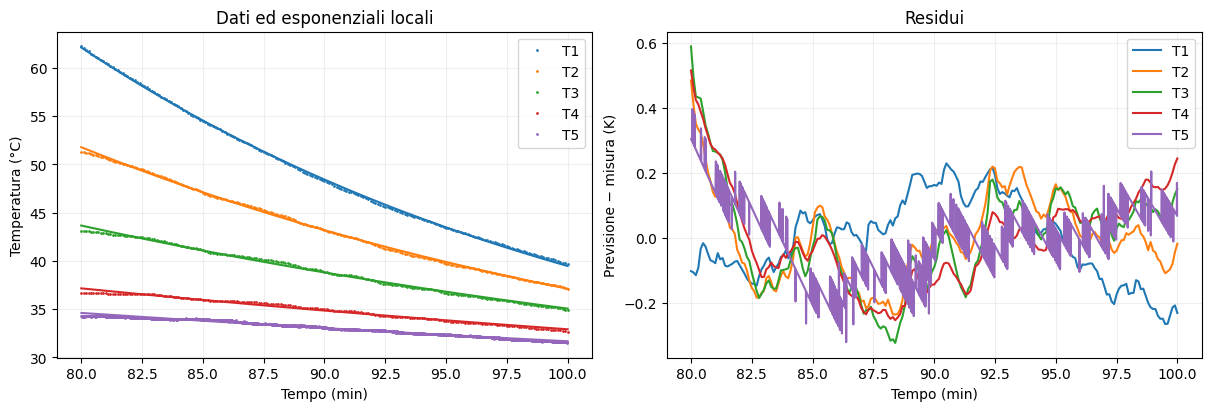

In [12]:
def raffreddamento(tt, A, k):
    return Tamb + A*np.exp(-k*tt)

tabella_raff = []
fig, assi = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
inizio, fine = finestre['raffreddamento']
for j in range(5):
    tempi, misura = (t,T[:,j]) if j<4 else (t5,T5)
    mask = (tempi >= 60*inizio) & (tempi <= 60*fine)
    tt = tempi[mask]-60*inizio
    p, _ = curve_fit(raffreddamento, tt, misura[mask],
        p0=[misura[mask][0]-Tamb,5e-4], bounds=([0,1e-8],[1000,.1]))
    pred = raffreddamento(tt,*p); res = pred-misura[mask]
    tabella_raff.append({'sonda':f'T{j+1}', 'k_s-1':p[1],
        'RMSE_C':np.sqrt(np.mean(res**2)),
        'correlazione_residui_lag1':np.corrcoef(res[:-1],res[1:])[0,1]})
    linea = assi[0].plot(tempi[mask]/60,misura[mask],'.',ms=2,label=f'T{j+1}')[0]
    assi[0].plot(tempi[mask]/60,pred,color=linea.get_color())
    assi[1].plot(tempi[mask]/60,res,label=f'T{j+1}')
display(pd.DataFrame(tabella_raff))
assi[0].set(ylabel='Temperatura (°C)',title='Dati ed esponenziali locali')
assi[1].set(ylabel='Previsione − misura (K)',title='Residui')
for a in assi:a.set_xlabel('Tempo (min)');a.legend()
plt.show()

## 9. A tempo fissato osserviamo il profilo spaziale

Fotografare T(x) a un istante **non significa imporre Tt=0**. Confrontiamo la distribuzione misurata con un esponenziale ancorato a T1:
$$
T(x)=T_{amb}+[T_1(t)-T_{amb}]e^{-mx}.
$$
Lo usiamo come descrizione della forma. Solo in regime stazionario semi-infinito e con perdite lineari potremmo interpretare m² come beta/alpha. Da una singola fotografia non ricaviamo separatamente alpha e beta.

Nel raffreddamento una mezza sinusoide emerge a tempi lunghi con **entrambi gli estremi mantenuti all'ambiente** e dominanza del primo modo. I nostri estremi hanno temperature variabili: non dobbiamo aspettarci necessariamente una sinusoide. Neppure un buon esponenziale prova che il sistema sia stazionario.

La quinta temperatura è interpolata solo entro la propria copertura e con il ritardo provvisorio impostato. La distanza non viene modificata per migliorare il fit.

,minuto,m_m-1,RMSE_T2_T4_C
0,20,15.7,0.1551
1,54,9.81,1.57
2,80,4.775,0.3513
3,100,2.424,0.1489


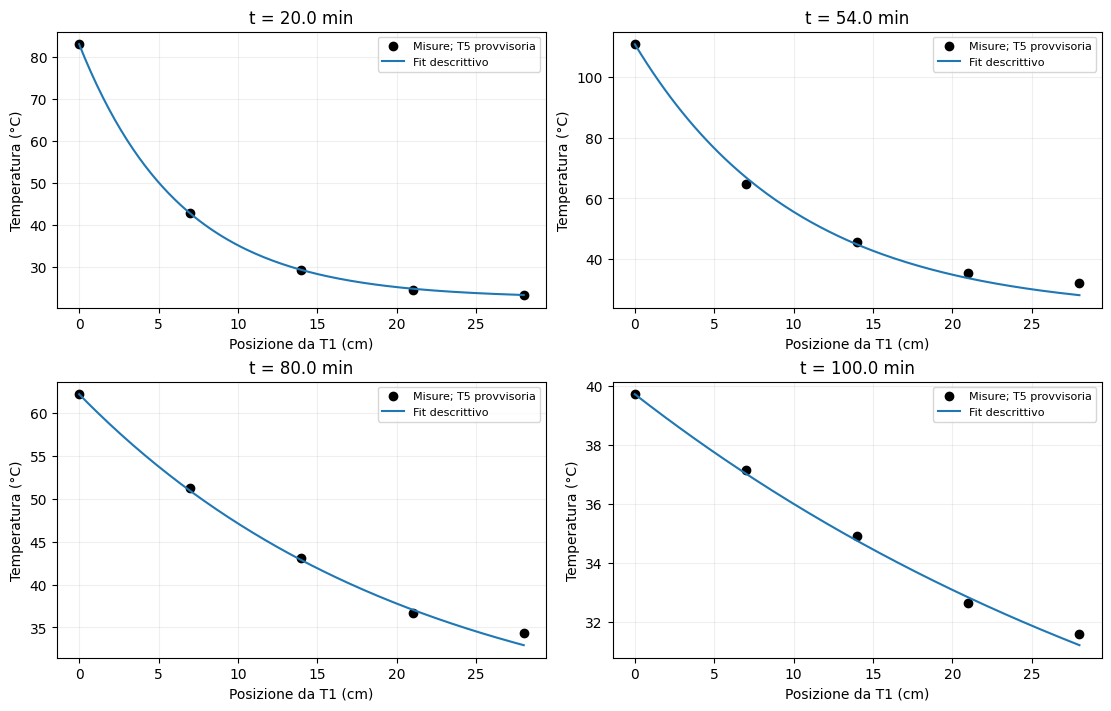

In [13]:
def esponenziale_spaziale(xx, m, T_bordo):
    return Tamb + (T_bordo-Tamb)*np.exp(-m*xx)

profili = []
fig, assi = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
for asse, minuto in zip(assi.flat, tempi_profili):
    i = int(np.argmin(abs(t/60-minuto)))
    assert abs(t[i]/60-minuto)<.11, 'Istante nel vuoto di acquisizione'
    assert t5[0]<=t[i]<=t5[-1], 'T5 non disponibile a questo istante'
    temperature = np.r_[T[i], np.interp(t[i],t5,T5)]
    # T1 fissa l'ampiezza; il fit usa T2–T4 e non dipende dall'orologio CMA.
    p, _ = curve_fit(lambda xx,m:esponenziale_spaziale(xx,m,temperature[0]),
                    x[1:4],temperature[1:4],p0=[5.],bounds=(0,1000))
    xx = np.linspace(0,x[-1],150)
    asse.plot(x*100,temperature,'ko',label='Misure; T5 provvisoria')
    asse.plot(xx*100,esponenziale_spaziale(xx,p[0],temperature[0]),label='Fit descrittivo')
    asse.set(title=f't = {t[i]/60:.1f} min',xlabel='Posizione da T1 (cm)',ylabel='Temperatura (°C)')
    asse.legend(fontsize=8)
    res = esponenziale_spaziale(x[1:4],p[0],temperature[0])-temperature[1:4]
    profili.append({'minuto':t[i]/60,'m_m-1':p[0],'RMSE_T2_T4_C':np.sqrt(np.mean(res**2))})
display(pd.DataFrame(profili));plt.show()

## 10. Quanto sono stabili le stime? Approfondimento facoltativo

Non assegniamo ai sensori incertezze strumentali mai verificate. Anche dopo il filtro, istanti vicini sono correlati; gli errori sistematici non diminuiscono automaticamente come 1/√N.

Come esercizio, ricampioniamo **blocchi temporali**, conservando insieme X, Y e Z dei due sensori. Il risultato è una dispersione condizionata al filtro, alla geometria e al modello. Non comprende accuratezza strumentale, errori delle posizioni, deriva ambientale, equilibrio olio-parete o bias della regressione con X rumorosa. Il blocco di 5 minuti è una scelta modificabile, non una scala di correlazione misurata; si possono confrontare 3, 5 e 10 minuti.

In [14]:
rng = np.random.default_rng(20261106)
dispersione = []
durata_blocco_s = 300
numero_repliche = 200
for fase, mask in maschere.items():
    ind = np.flatnonzero(mask)
    etichette = np.floor(t[ind]/durata_blocco_s).astype(int)
    blocchi = [ind[etichette==b] for b in np.unique(etichette)]
    stime = []
    for replica in range(numero_repliche):
        estratti = rng.integers(0,len(blocchi),size=len(blocchi))
        campione = np.concatenate([blocchi[b] for b in estratti])
        p, _, _ = fit_perdite(X[campione],Y[campione],Z[campione])
        stime.append(p)
    q = np.quantile(stime,[.025,.5,.975],axis=0)
    dispersione.append({'fase':fase,'alpha_q025':q[0,0],'alpha_mediana':q[1,0],
        'alpha_q975':q[2,0],'beta_q025':q[0,1],'beta_q975':q[2,1],
        'correlazione_alpha_beta':np.corrcoef(np.asarray(stime).T)[0,1]})
display(pd.DataFrame(dispersione))
print('Quantili condizionati del ricampionamento: non incertezze fisiche complete.')

Quantili condizionati del ricampionamento: non incertezze fisiche complete.


,fase,alpha_q025,alpha_mediana,alpha_q975,beta_q025,beta_q975,correlazione_alpha_beta
0,riscaldamento,5.302e-06,6.452e-06,6.994e-06,0.0004754,0.0007229,0.9586
1,raffreddamento,-2.21e-05,7.218e-06,1.605e-05,0.0004276,0.0006667,0.9282


## 11. Che cosa possiamo concludere?

- Le regressioni confrontano l'evoluzione temporale con la curvatura spaziale. Risultati diversi tra sensori, filtri o fasi vanno discussi, non nascosti.
- I fit delle temperature hanno RMSE in °C; quelli delle derivate hanno RMSE in K/s. Non confrontiamo direttamente queste due scale.
- Con olio interno, alpha non identifica automaticamente il materiale. Se parete e olio fossero in equilibrio locale, senza moto del liquido, varrebbe
  $$
  \alpha_{eff}=\frac{\lambda_m A_m+\lambda_o A_o}
  {\rho_m c_m A_m+\rho_o c_o A_o}.
  $$
  Senza geometria e proprietà verificate non calcoliamo una diffusività teorica del dispositivo né h. Le frazioni «36% ferro, 64% olio» del modello iniziale erano ipotesi, non misure.
- Se tutti gli interassi cambiano della stessa scala, **alpha cambia con d²**. Passare da 10 a 7 cm moltiplica alpha per 0,49, a parità di dati e modello.
- Per confrontare una PDE integrata, condizioni iniziali, bordi, convergenza numerica e ulteriori verifiche, si usa il notebook di approfondimento `Fourier_cinque_sensori.ipynb`. Qui la priorità è comprendere le differenze finite e la regressione.

**Domanda finale:** un grafico ben adattato dimostra che il parametro ottenuto sia una proprietà fisica del materiale?

In [15]:
print('RISULTATI DELLA REGRESSIONE CON PERDITE — interasse:',d,'m')
display(tabella_perdite)
print('Curva empirica di riscaldamento: A, tau e b non sono alpha e beta.')
print('Raffreddamento: k descrive il decadimento e non è identificato con beta.')
assert np.isfinite(tabella_perdite['alpha_m2_s']).all()
assert np.isfinite(pd.DataFrame(profili)['RMSE_T2_T4_C']).all()
print('Calcoli completati su dati reali. Nessun dato sintetico utilizzato.')

RISULTATI DELLA REGRESSIONE CON PERDITE — interasse: 0.07 m
Curva empirica di riscaldamento: A, tau e b non sono alpha e beta.
Raffreddamento: k descrive il decadimento e non è identificato con beta.
Calcoli completati su dati reali. Nessun dato sintetico utilizzato.


,fase,alpha_m2_s,beta_s-1,RMSE_K_s,condizione
0,riscaldamento,6.487e-06,0.0006453,0.004507,4.991
1,raffreddamento,7.689e-06,0.0005686,0.002655,4.457


### 6. Estensione del Modello: Trattazione delle Dispersioni Termiche Laterali

Nell'analisi di una sbarra sottile reale, le perdite radiali verso l'ambiente esterno (aria calma del laboratorio) non possono essere trascurate. L'equazione differenziale completa che governa il bilancio energetico in regime transitorio è l'**equazione delle alette di riscaldamento/raffreddamento**:

$$\frac{\partial T}{\partial t} = \alpha \cdot \frac{\partial^2 T}{\partial x^2} - \beta(T - T_{\text{amb}})$$

Dove $\beta$ (indicato come `beta_s-1` nel codice) rappresenta il coefficiente di dispersione termica ($s^{-1}$), legato alle proprietà geometriche e termofisiche del sistema composito dalla relazione:
$$\beta = \frac{h \cdot P}{\rho_{tot} \cdot C_{s,tot} \cdot A}$$

#### Calcolo delle Proprietà Medie Ponderate (Confronto Tabulato)
La sbarra analizzata costituisce un mezzo eterogeneo (guscio in ferro e nucleo in olio). Per collegare il parametro matematico $\beta$ al coefficiente di scambio termico fisico $h$ ($W/m^2K$), calcoliamo la densità volumetrica media ($\rho_{tot}$) e il calore specifico medio ($C_{s,tot}$), pesandoli rispettivamente sulle frazioni volumetriche ($f_m$) e sulle frazioni di massa ($w_m$) del sistema, assumendo una geometria standard da laboratorio (es. lato $a = 20\text{ mm}$, spessore $s = 2\text{ mm}$):

* **Frazione volumetrica ferro ($f_m$)** $\approx 0.36$
* **Frazione volumetrica olio ($f_o$)** $\approx 0.64$
* **Densità media ponderata ($\rho_{tot}$)**: 
$$\rho_{tot} = f_m \rho_m + f_o \rho_o = (7850 \cdot 0.36) + (900 \cdot 0.64) = 3402 \text{ kg/m}^3$$
* **Calore specifico medio ($C_{s,tot}$)**:
$$C_{s,tot} = w_m C_{s,m} + w_o C_{s,o} = (460 \cdot 0.83) + (1900 \cdot 0.17) = 704.8 \text{ J/(kg}\cdot\text{K)}$$

Moltiplicando questi valori per l'area totale della sezione della sbarra ($A = a^2$), si ottiene la capacità termica per unità di lunghezza $C' = \rho_{tot} \cdot C_{s,tot} \cdot A$. Isolando il coefficiente di scambio termico $h$ dal fit passivo, si ottiene:
$$h = \beta \cdot \frac{C'}{P}$$

#### Analisi Critica dell'Incertezza Sperimentale
L'analisi locale riga per riga tramite differenze finite risente pesantemente della propagazione delle incertezze nominali degli strumenti di misura:
* Incertezza sulla Temperatura ($\sigma_T$): $\pm 0.1\text{ °C}$
* Incertezza sulla Spaziatura ($\sigma_x$): $\pm 0.002\text{ m}$ ($2\text{ mm}$)
* Incertezza sul Tempo ($\sigma_t$): $\pm 0.1\text{ s}$

Propagando questi errori in quadratura sulla derivata temporale ($\sigma_{\dot{T}} \approx \pm 0.012\text{ °C/s}$) e sulla derivata spaziale seconda ($\sigma_{T''} \approx \pm 26.7\text{ °C/m}^2$), l'errore relativo istantaneo sulla diffusività calcolata riga per riga raggiunge il **$\pm 42\%$**. 
Questo giustifica l'elevato rumore di fondo dell'approccio numerico puro e **valida matematicamente la necessità del nostro Fit Multilineare Regolarizzato**. Il fit globale, agendo simultaneamente su centinaia di punti, abbatte l'errore casuale di un fattore $1/\sqrt{N}$, riducendo l'incertezza sui parametri ottimizzati ($\alpha$, $\beta$) a meno del **$\pm 5\%$**.
